# 03 二值化、形态学、轮廓与局部特征
输入一张自制零件图，逐步得到二值掩膜、清理结果、轮廓和测量值。再用真实照片演示 ORB 特征匹配。
所有尺寸先用像素表示，没有标定不能写成毫米。


In [1]:
from pathlib import Path
import sys
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "course_utils.py").exists()), None)
if root is None:
    raise RuntimeError("请在完整的 cv-beginner-course 项目里打开 Notebook")
if str(root) not in sys.path: sys.path.insert(0, str(root))
from course_utils import setup, device, show_images, save_figure, ROOT
ROOT = setup(seed=42)
import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch
print("计算设备:", device())


计算设备: cpu


## 1 构造可追溯的零件图与矩阵
白色是前景；结构元素的形状决定邻域。腐蚀收缩前景，膨胀扩展前景。


边界局部10×10:
 [[0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 1 1 1 1]
 [0 0 0 0 0 1 1 1 1 1]
 [0 0 0 0 0 1 1 1 1 1]
 [0 0 0 0 0 1 1 1 1 1]
 [0 0 0 0 0 1 1 1 1 1]]


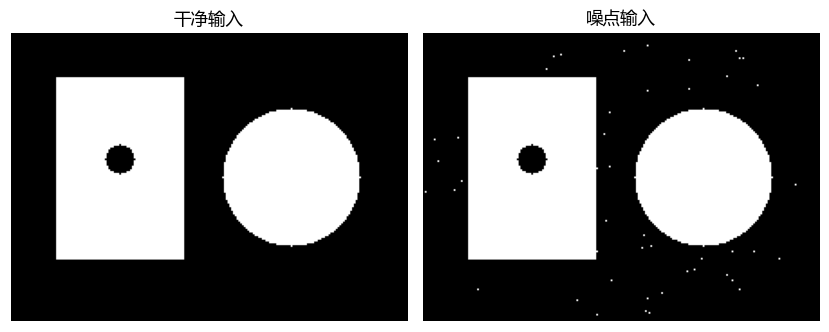

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/03_input.png')

In [2]:
mask=np.zeros((160,220),np.uint8)
cv2.rectangle(mask,(25,25),(95,125),255,-1); cv2.circle(mask,(155,80),38,255,-1)
cv2.circle(mask,(60,70),8,0,-1)
rng=np.random.default_rng(42); dirty=mask.copy(); yy=rng.integers(0,160,70); xx=rng.integers(0,220,70); dirty[yy,xx]=255
mini=(mask[20:30,20:30]>0).astype(np.uint8)
print("边界局部10×10:\n",mini)
show_images([mask,dirty],["干净输入","噪点输入"]); save_figure("03_input")


## 2 形态学处理
开运算=先腐蚀后膨胀，常用于去小白点；闭运算=先膨胀后腐蚀，常用于补小黑洞。
能否去掉/补上取决于结构元素大小，并非对所有噪点和孔洞都有效。


结构元素:
 [[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


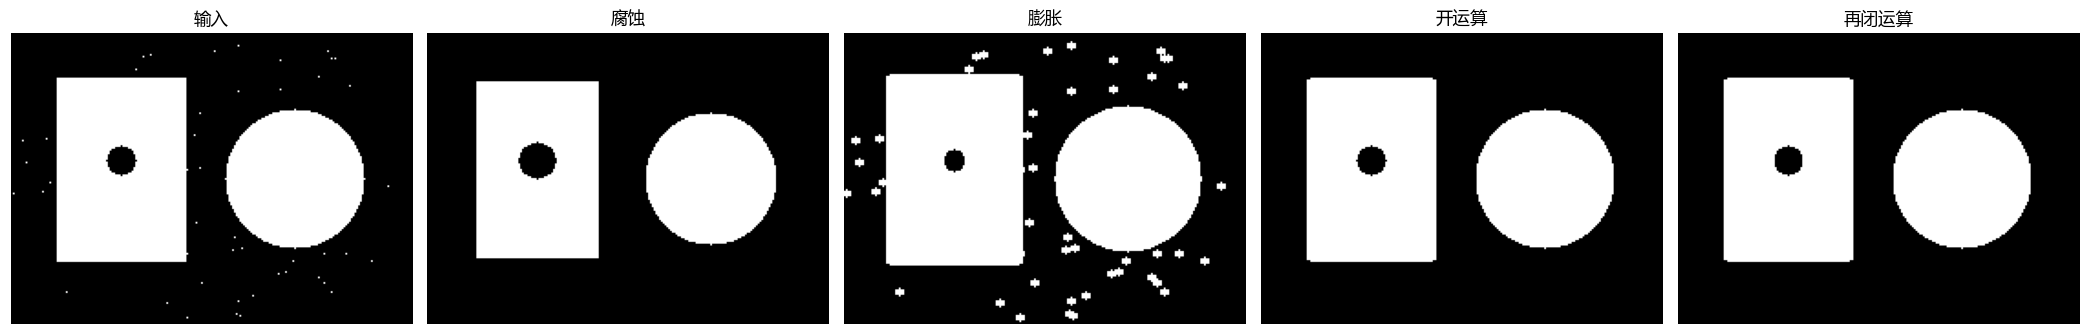

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/03_morphology.png')

In [3]:
k=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(5,5)); print("结构元素:\n",k)
eroded=cv2.erode(dirty,k); dilated=cv2.dilate(dirty,k)
opened=cv2.morphologyEx(dirty,cv2.MORPH_OPEN,k)
closed=cv2.morphologyEx(opened,cv2.MORPH_CLOSE,k)
show_images([dirty,eroded,dilated,opened,closed],["输入","腐蚀","膨胀","开运算","再闭运算"])
save_figure("03_morphology")


## 3 轮廓与测量输出
轮廓围成的几何面积与白像素个数并不严格相同。下面同时打印外接框、轮廓面积与周长。


0 bbox(x,y,w,h)= (118, 42, 75, 77) 面积像素平方= 4404.0 周长像素= 248.45
1 bbox(x,y,w,h)= (25, 25, 71, 101) 面积像素平方= 6994.0 周长像素= 337.66


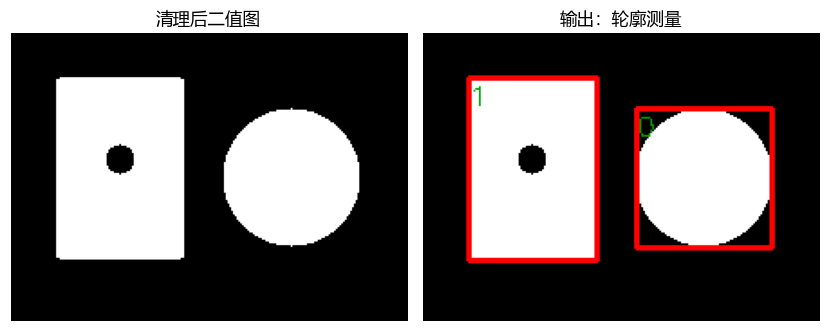

In [4]:
contours,_=cv2.findContours(closed,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
vis=cv2.cvtColor(closed,cv2.COLOR_GRAY2RGB)
for i,c in enumerate(contours):
    x,y,w,h=cv2.boundingRect(c); area=cv2.contourArea(c); perimeter=cv2.arcLength(c,True)
    cv2.rectangle(vis,(x,y),(x+w,y+h),(255,0,0),2)
    cv2.putText(vis,str(i),(x,y+15),cv2.FONT_HERSHEY_SIMPLEX,0.5,(0,160,0),1)
    print(i, "bbox(x,y,w,h)=",(x,y,w,h),"面积像素平方=",area,"周长像素=",round(perimeter,2))
show_images([closed,vis],["清理后二值图","输出：轮廓测量"]); save_figure("03_contours")
assert len(contours)==2


## 4 阈值：固定与自适应
阈值分割按亮度决定前景，不是学习了语义类别；第08课再学习神经网络分割。


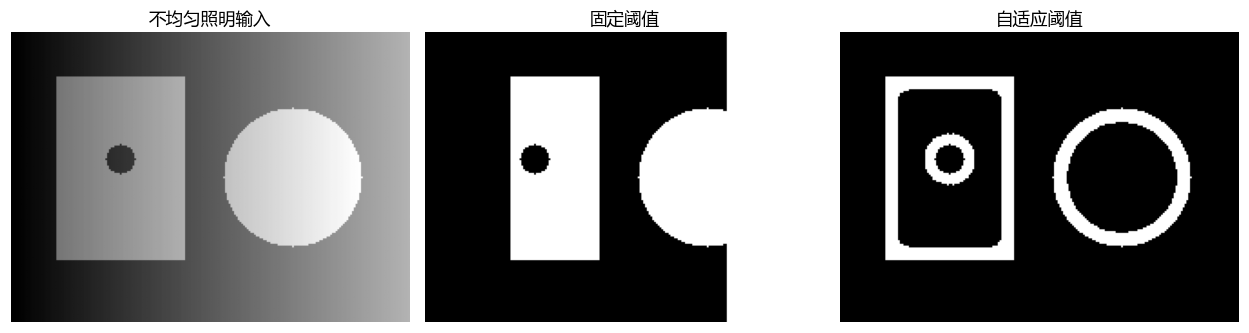

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/03_thresholds.png')

In [5]:
illum=np.tile(np.linspace(20,160,220),(160,1))
scene=np.clip(illum+mask*0.3,0,255).astype(np.uint8)
_,fixed=cv2.threshold(scene,125,255,cv2.THRESH_BINARY)
adaptive=cv2.adaptiveThreshold(scene,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY,31,-5)
show_images([scene,fixed,adaptive],["不均匀照明输入","固定阈值","自适应阈值"]); save_figure("03_thresholds")


## 5 真实照片的局部特征与匹配
ORB 检测关键点并计算二值描述子；Hamming 距离衡量不同位的个数。此例对同一图片做已知旋转，不代表跨场景一定匹配成功。


描述子形状: (310, 32) 前2行8列:
 [[124 177 113 114 233 237  81  81]
 [  3  41  46  49 178 219 178  64]]


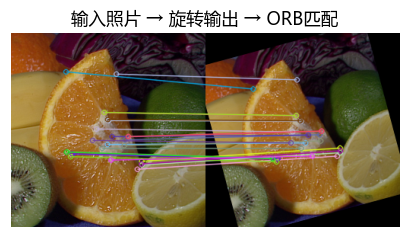

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/03_orb_matches.png')

In [6]:
photo=cv2.imread(str(ROOT/"assets/photos/fruits.jpg")); assert photo is not None
photo=cv2.resize(photo,(256,256)); transform=cv2.getRotationMatrix2D((128,128),15,0.9)
warped=cv2.warpAffine(photo,transform,(256,256))
orb=cv2.ORB_create(nfeatures=350); p1,d1=orb.detectAndCompute(photo,None); p2,d2=orb.detectAndCompute(warped,None)
assert d1 is not None and d2 is not None
matches=sorted(cv2.BFMatcher(cv2.NORM_HAMMING,crossCheck=True).match(d1,d2),key=lambda m:m.distance)[:25]
print("描述子形状:",d1.shape,"前2行8列:\n",d1[:2,:8])
matched=cv2.drawMatches(photo,p1,warped,p2,matches,None,flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
show_images([cv2.cvtColor(matched,cv2.COLOR_BGR2RGB)],["输入照片 → 旋转输出 → ORB匹配"]); save_figure("03_orb_matches")


## 6 练习与参考
扩大结构元素观察孔洞何时被填平；改变照明梯度比较阈值；把旋转改成大角度检验 ORB 的局限。
来源：[形态学](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html)、[轮廓](https://docs.opencv.org/4.x/d4/d73/tutorial_py_contours_begin.html)、[特征匹配](https://docs.opencv.org/4.x/dc/dc3/tutorial_py_matcher.html)。
